# Projekt 2: siec neuronowa MLP dla klasyfikacji fetal health

**Cel:** sprawdzic, czy mala siec neuronowa typu **MLP** potrafi klasyfikowac
stan zdrowia plodu na podstawie cech tabelarycznych z pomiarow CTG.

Notebook jest pierwsza wersja projektu 2 na tym samym zbiorze co projekt 1.
Obecny CSV zawiera gotowe cechy liczbowe, a nie surowy sygnal czasowy CTG,
dlatego naturalna architektura startowa to MLP. Modele CNN, RNN i LSTM
mialyby wiecej sensu dopiero dla surowych sekwencji pomiarowych.

## Plan eksperymentu

1. Wczytanie i szybka kontrola zbioru.
2. Stratyfikowany podzial train/test.
3. Selekcja silnie skorelowanych cech liczona tylko na train.
4. Skalowanie cech i trening malej sieci MLP.
5. Porownanie baseline oraz wariantu z `SMOTE`.
6. Tuning malej architektury MLP przez cross-validation.
7. Ewaluacja na odlozonym zbiorze testowym i porownanie z projektem 1.

Glowna metryka to **macro F1**, bo klasy sa wyraznie niezbalansowane.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

CLASS_LABELS = {
    1: "Normal",
    2: "Suspect",
    3: "Pathological",
}

print("Biblioteki zaladowane.")

Biblioteki zaladowane.


## 1. Wczytanie i kontrola danych

In [2]:
df = pd.read_csv("fetal_health.csv")
df.columns = df.columns.str.replace(" ", "_", regex=False)
df["fetal_health"] = df["fetal_health"].astype(int)

print(f"Wymiary zbioru: {df.shape[0]} rekordow, {df.shape[1]} kolumn")
print(f"Brakujace wartosci: {df.isna().sum().sum()}")
print(f"Duplikaty: {df.duplicated().sum()}")
df.head()

Wymiary zbioru: 2126 rekordow, 22 kolumn
Brakujace wartosci: 0
Duplikaty: 13


,baseline_value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1


In [3]:
feature_columns = df.columns.drop("fetal_health")
feature_summary = pd.DataFrame(
    {
        "dtype": df[feature_columns].dtypes.astype(str),
        "min": df[feature_columns].min(),
        "median": df[feature_columns].median(),
        "max": df[feature_columns].max(),
        "std": df[feature_columns].std(),
    }
).round(4)

feature_summary

,dtype,min,median,max,std
baseline_value,float64,106.0,133.000,160.000,9.8408
accelerations,float64,0.0,0.002,0.019,0.0039
fetal_movement,float64,0.0,0.000,0.481,0.0467
uterine_contractions,float64,0.0,0.004,0.015,0.0029
light_decelerations,float64,0.0,0.000,0.015,0.0030
severe_decelerations,float64,0.0,0.000,0.001,0.0001
prolongued_decelerations,float64,0.0,0.000,0.005,0.0006
abnormal_short_term_variability,float64,12.0,49.000,87.000,17.1928
mean_value_of_short_term_variability,float64,0.2,1.200,7.000,0.8832
percentage_of_time_with_abnormal_long_term_variability,float64,0.0,0.000,91.000,18.3969


,label,records,share_percent
fetal_health,,,
1,Normal,1655,77.8
2,Suspect,295,13.9
3,Pathological,176,8.3


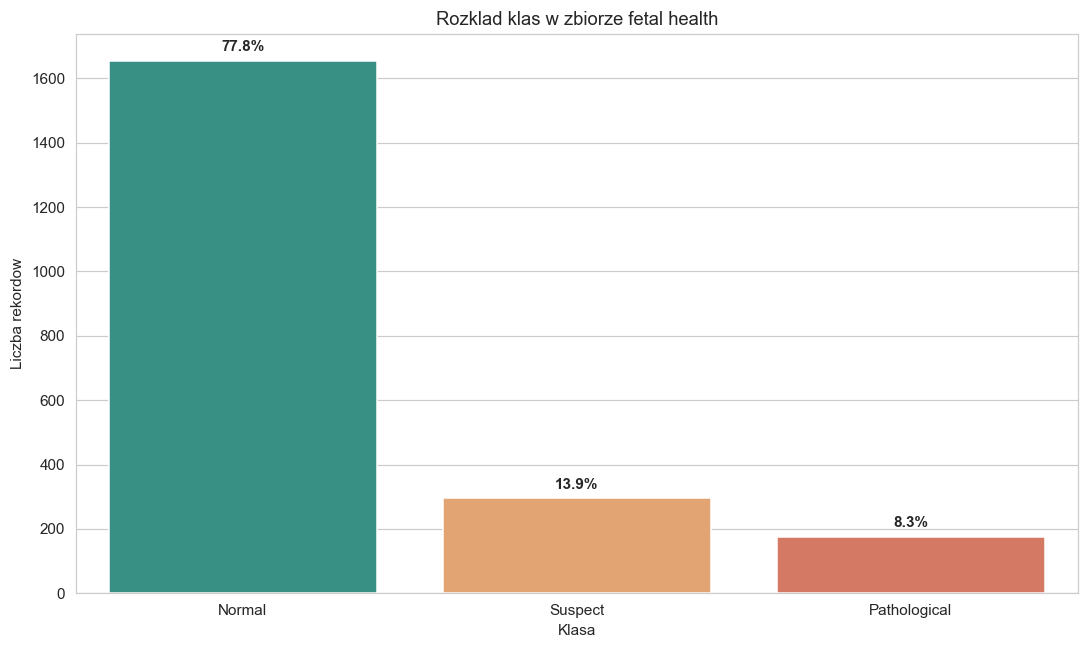

In [4]:
class_counts = df["fetal_health"].value_counts().sort_index()
class_percent = (class_counts / len(df) * 100).round(1)
class_table = pd.DataFrame(
    {
        "label": [CLASS_LABELS[i] for i in class_counts.index],
        "records": class_counts,
        "share_percent": class_percent,
    }
)

display(class_table)

ax = sns.barplot(
    data=class_table,
    x="label",
    y="records",
    hue="label",
    palette=["#2a9d8f", "#f4a261", "#e76f51"],
    legend=False,
)
for row_index, row in class_table.reset_index(drop=True).iterrows():
    ax.text(
        row_index,
        row["records"] + 20,
        f'{row["share_percent"]:.1f}%',
        ha="center",
        va="bottom",
        fontweight="bold",
    )
ax.set_title("Rozklad klas w zbiorze fetal health")
ax.set_xlabel("Klasa")
ax.set_ylabel("Liczba rekordow")
plt.tight_layout()
plt.show()

## 2. Podzial danych i selekcja cech

Siec MLP jest wrazliwa na skale cech, wiec skalowanie trafi pozniej do
pipeline. Najpierw odkladamy test i usuwamy wybrane silnie skorelowane
cechy na podstawie macierzy korelacji liczonej **wylacznie na train**.

In [5]:
X = df.drop(columns="fetal_health")
y = df["fetal_health"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

corr_train = X_train.corr().abs()
upper_triangle = corr_train.where(
    np.triu(np.ones(corr_train.shape), k=1).astype(bool)
)
correlated_to_drop = [
    column for column in upper_triangle.columns
    if (upper_triangle[column] > 0.85).any()
]

X_train_selected = X_train.drop(columns=correlated_to_drop)
X_test_selected = X_test.drop(columns=correlated_to_drop)

print(f"Train: {X_train_selected.shape}")
print(f"Test:  {X_test_selected.shape}")
print(f"Usuniete cechy: {correlated_to_drop}")
print(f"Pozostale cechy ({X_train_selected.shape[1]}):")
print(X_train_selected.columns.tolist())
print("\nRozklad klas w train:")
print(y_train.value_counts().sort_index())
print("\nRozklad klas w test:")
print(y_test.value_counts().sort_index())

Train: (1700, 18)
Test:  (426, 18)
Usuniete cechy: ['histogram_min', 'histogram_mean', 'histogram_median']
Pozostale cechy (18):
['baseline_value', 'accelerations', 'fetal_movement', 'uterine_contractions', 'light_decelerations', 'severe_decelerations', 'prolongued_decelerations', 'abnormal_short_term_variability', 'mean_value_of_short_term_variability', 'percentage_of_time_with_abnormal_long_term_variability', 'mean_value_of_long_term_variability', 'histogram_width', 'histogram_max', 'histogram_number_of_peaks', 'histogram_number_of_zeroes', 'histogram_mode', 'histogram_variance', 'histogram_tendency']

Rozklad klas w train:
fetal_health
1    1323
2     236
3     141
Name: count, dtype: int64

Rozklad klas w test:
fetal_health
1    332
2     59
3     35
Name: count, dtype: int64


## 3. Baseline: mala siec MLP

`MLPClassifier` implementuje wielowarstwowy perceptron z warstwami gestymi.
Baseline ma dwie male warstwy ukryte `(64, 32)`, aktywacje ReLU,
regularyzacje `alpha` oraz early stopping.

In [6]:
def make_mlp(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3):
    return MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation="relu",
        solver="adam",
        alpha=alpha,
        batch_size=32,
        learning_rate_init=learning_rate_init,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=RANDOM_STATE,
    )


mlp_baseline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", make_mlp()),
    ]
)
mlp_smote = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", make_mlp()),
    ]
)

mlp_baseline.fit(X_train_selected, y_train)
mlp_smote.fit(X_train_selected, y_train)

baseline_predictions = mlp_baseline.predict(X_test_selected)
smote_predictions = mlp_smote.predict(X_test_selected)

In [7]:
def metric_row(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro"),
        "Recall_macro": recall_score(y_true, y_pred, average="macro"),
        "F1_macro": f1_score(y_true, y_pred, average="macro"),
        "F1_Normal": f1_score(y_true, y_pred, average=None, labels=[1, 2, 3])[0],
        "F1_Suspect": f1_score(y_true, y_pred, average=None, labels=[1, 2, 3])[1],
        "F1_Pathological": f1_score(y_true, y_pred, average=None, labels=[1, 2, 3])[2],
    }


baseline_comparison = pd.DataFrame(
    [
        metric_row("MLP baseline", y_test, baseline_predictions),
        metric_row("MLP + SMOTE", y_test, smote_predictions),
    ]
).set_index("Model")

baseline_comparison.round(4)

,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_Normal,F1_Suspect,F1_Pathological
Model,,,,,,,
MLP baseline,0.8920,0.8045,0.7803,0.7915,0.9445,0.6723,0.7576
MLP + SMOTE,0.8991,0.8179,0.8306,0.8241,0.9440,0.6833,0.8451


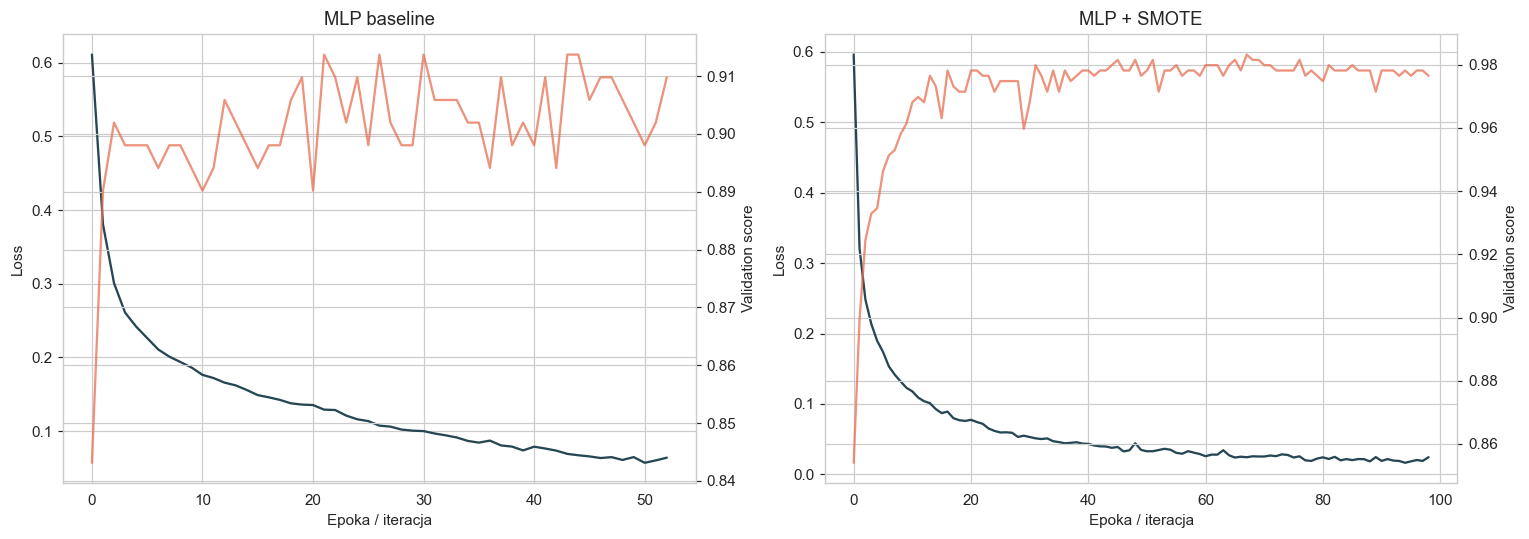

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, pipeline, title in [
    (axes[0], mlp_baseline, "MLP baseline"),
    (axes[1], mlp_smote, "MLP + SMOTE"),
]:
    model = pipeline.named_steps["model"]
    ax.plot(model.loss_curve_, label="train loss", color="#264653")
    if hasattr(model, "validation_scores_") and model.validation_scores_:
        second_axis = ax.twinx()
        second_axis.plot(
            model.validation_scores_,
            label="validation score",
            color="#e76f51",
            alpha=0.75,
        )
        second_axis.set_ylabel("Validation score")
    ax.set_title(title)
    ax.set_xlabel("Epoka / iteracja")
    ax.set_ylabel("Loss")

plt.tight_layout()
plt.show()

## 4. Tuning architektury i regularyzacji

Szukamy tylko malych sieci. Przy 2126 rekordach zbyt duza architektura
latwo nauczy sie szczegolow train zamiast stabilnych zaleznosci.

`SMOTE` pozostaje w pipeline, wiec nowe probki sa generowane tylko
wewnatrz foldow treningowych cross-validation.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

tuning_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", make_mlp()),
    ]
)

param_grid = {
    "model__hidden_layer_sizes": [(32,), (64,), (32, 16), (64, 32)],
    "model__alpha": [1e-4, 1e-3, 1e-2],
    "model__learning_rate_init": [5e-4, 1e-3],
}

mlp_grid = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)
mlp_grid.fit(X_train_selected, y_train)

print(f"Najlepsze parametry: {mlp_grid.best_params_}")
print(f"Najlepszy wynik CV macro F1: {mlp_grid.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Najlepsze parametry: {'model__alpha': 0.001, 'model__hidden_layer_sizes': (64,), 'model__learning_rate_init': 0.001}
Najlepszy wynik CV macro F1: 0.8619


In [10]:
cv_results = (
    pd.DataFrame(mlp_grid.cv_results_)
    .sort_values("rank_test_score")
    [
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "param_model__hidden_layer_sizes",
            "param_model__alpha",
            "param_model__learning_rate_init",
        ]
    ]
    .head(10)
)

cv_results.round(4)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_model__hidden_layer_sizes,param_model__alpha,param_model__learning_rate_init
11,1,0.8619,0.0125,0.9552,"(64,)",0.0010,0.0010
6,2,0.8596,0.0150,0.9744,"(64, 32)",0.0001,0.0005
2,3,0.8586,0.0107,0.9463,"(64,)",0.0001,0.0005
18,4,0.8577,0.0094,0.9518,"(64,)",0.0100,0.0005
22,5,0.8576,0.0139,0.9728,"(64, 32)",0.0100,0.0005
5,6,0.8570,0.0217,0.9700,"(32, 16)",0.0001,0.0010
3,7,0.8565,0.0102,0.9564,"(64,)",0.0001,0.0010
10,8,0.8559,0.0128,0.9494,"(64,)",0.0010,0.0005
15,9,0.8554,0.0219,0.9780,"(64, 32)",0.0010,0.0010
21,10,0.8548,0.0232,0.9684,"(32, 16)",0.0100,0.0010


## 5. Ewaluacja najlepszego MLP na tescie

In [11]:
best_mlp = mlp_grid.best_estimator_
best_predictions = best_mlp.predict(X_test_selected)

tuned_metrics = pd.DataFrame(
    [metric_row("MLP tuned + SMOTE", y_test, best_predictions)]
).set_index("Model")
tuned_metrics.round(4)

,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_Normal,F1_Suspect,F1_Pathological
Model,,,,,,,
MLP tuned + SMOTE,0.892,0.8077,0.8462,0.8248,0.937,0.6923,0.8451


Classification report - najlepszy MLP
                  precision    recall  f1-score   support

      1 - Normal       0.96      0.92      0.94       332
     2 - Suspect       0.63      0.76      0.69        59
3 - Pathological       0.83      0.86      0.85        35

        accuracy                           0.89       426
       macro avg       0.81      0.85      0.82       426
    weighted avg       0.90      0.89      0.90       426



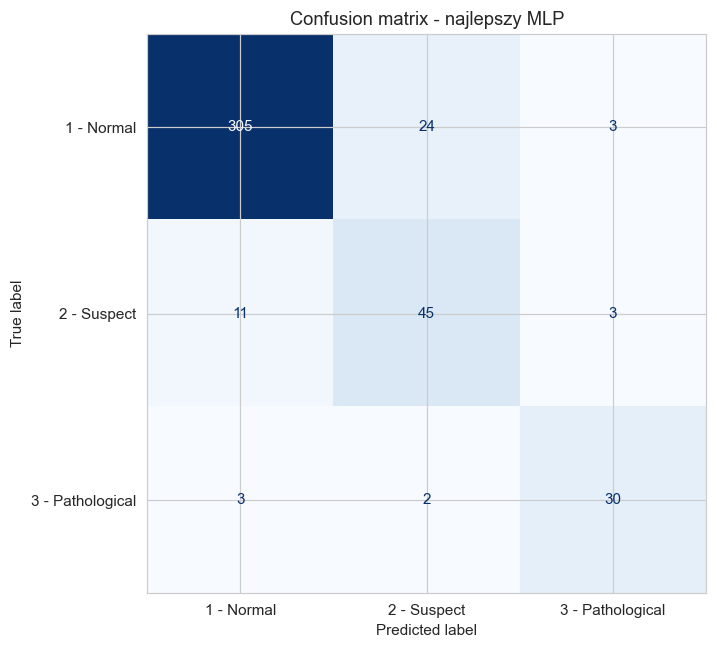

In [12]:
target_names = [f"{class_id} - {CLASS_LABELS[class_id]}" for class_id in [1, 2, 3]]

print("Classification report - najlepszy MLP")
print(classification_report(y_test, best_predictions, target_names=target_names))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=[1, 2, 3],
    display_labels=target_names,
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
ax.set_title("Confusion matrix - najlepszy MLP")
plt.tight_layout()
plt.show()

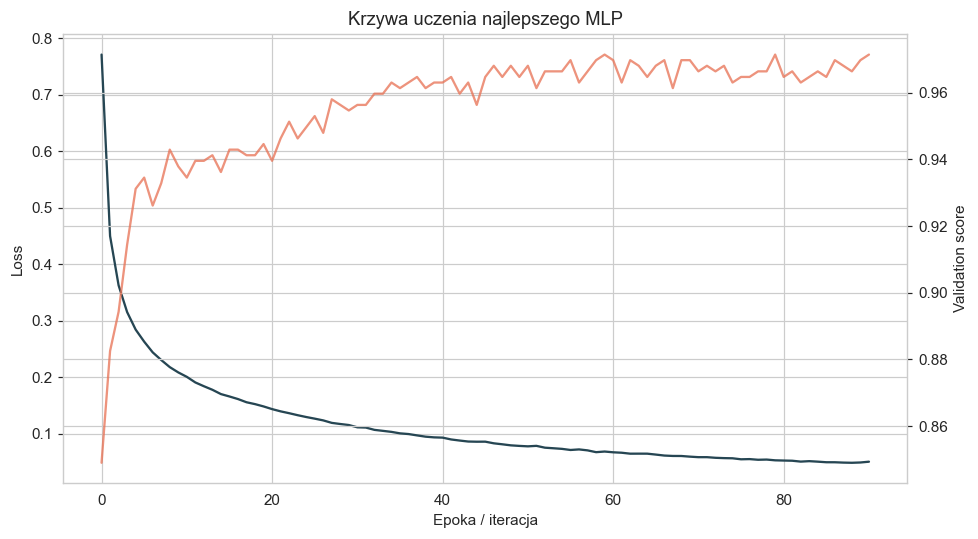

Liczba iteracji najlepszego MLP: 91
Najlepszy validation score w early stopping: 0.9714765100671141


In [13]:
best_model = best_mlp.named_steps["model"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(best_model.loss_curve_, color="#264653", label="train loss")
ax.set_xlabel("Epoka / iteracja")
ax.set_ylabel("Loss")
ax.set_title("Krzywa uczenia najlepszego MLP")

if hasattr(best_model, "validation_scores_") and best_model.validation_scores_:
    validation_axis = ax.twinx()
    validation_axis.plot(
        best_model.validation_scores_,
        color="#e76f51",
        label="validation score",
        alpha=0.75,
    )
    validation_axis.set_ylabel("Validation score")

plt.tight_layout()
plt.show()

print(f"Liczba iteracji najlepszego MLP: {best_model.n_iter_}")
print(
    "Najlepszy validation score w early stopping: "
    f"{getattr(best_model, 'best_validation_score_', None)}"
)

## 6. Porownanie z punktem odniesienia z projektu 1

Ponizsze metryki RF i XGBoost sa przepisane z pierwszego notebooka,
gdzie te modele byly ewaluowane na tym samym podziale `random_state=42`
i na tym samym zbiorze testowym.

In [14]:
project1_reference = pd.DataFrame(
    [
        {
            "Model": "Random Forest - projekt 1",
            "Accuracy": 0.9319,
            "Precision_macro": 0.8683,
            "Recall_macro": 0.8857,
            "F1_macro": 0.8768,
            "F1_Normal": 0.9636,
            "F1_Suspect": 0.7934,
            "F1_Pathological": 0.8732,
        },
        {
            "Model": "XGBoost - projekt 1",
            "Accuracy": 0.9460,
            "Precision_macro": 0.8973,
            "Recall_macro": 0.8863,
            "F1_macro": 0.8898,
            "F1_Normal": 0.9746,
            "F1_Suspect": 0.8182,
            "F1_Pathological": 0.8767,
        },
    ]
).set_index("Model")

final_comparison = pd.concat(
    [
        project1_reference,
        baseline_comparison,
        tuned_metrics,
    ]
)

final_comparison.round(4).sort_values("F1_macro", ascending=False)

,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_Normal,F1_Suspect,F1_Pathological
Model,,,,,,,
XGBoost - projekt 1,0.9460,0.8973,0.8863,0.8898,0.9746,0.8182,0.8767
Random Forest - projekt 1,0.9319,0.8683,0.8857,0.8768,0.9636,0.7934,0.8732
MLP tuned + SMOTE,0.8920,0.8077,0.8462,0.8248,0.9370,0.6923,0.8451
MLP + SMOTE,0.8991,0.8179,0.8306,0.8241,0.9440,0.6833,0.8451
MLP baseline,0.8920,0.8045,0.7803,0.7915,0.9445,0.6723,0.7576


## 7. Wnioski

Przeprowadzony eksperyment potwierdzil, ze cechy kardiotokograficzne ze zbioru
`fetal_health.csv` moga zostac wykorzystane do klasyfikacji wieloklasowej przez
mala siec neuronowa MLP. Dane nie zawieraly brakow, wszystkie cechy wejsciowe
byly liczbowe, a po usunieciu silnie skorelowanych kolumn model uczyl sie na
18 cechach. Ze wzgledu na rozne skale cech zastosowano standaryzacje, a z powodu
nierownowagi klas oceniano modele przede wszystkim przez `macro F1`.

### Wplyw SMOTE i tuningu

Bazowy MLP osiagnal na zbiorze testowym `macro F1 = 0.7915`. Dodanie `SMOTE`
w pipeline podnioslo ten wynik do `0.8241` i wyraznie poprawilo rozpoznawanie
klasy `Pathological` (`F1` wzroslo z `0.7576` do `0.8451`). Oznacza to, ze
uwzglednienie niezbalansowania klas bylo w tym zadaniu istotne.

Grid search wskazal niewielka architekture z jedna warstwa ukryta `(64,)`,
`alpha = 0.001` oraz `learning_rate_init = 0.001`. Najlepszy sredni wynik
cross-validation wyniosl `macro F1 = 0.8619`, natomiast na odlozonym zbiorze
testowym dostrojony model uzyskal `macro F1 = 0.8248`. Tuning nie zmienil
radykalnie wyniku testowego wzgledem prostego wariantu MLP z `SMOTE`, co sugeruje,
ze w tym zbiorze ograniczeniem jest nie tylko dobor hiperparametrow sieci.

### Jakosc klasyfikacji

Najlepszy MLP najpewniej rozpoznawal klase `Normal` (`F1 = 0.94`). Dla klasy
`Pathological` uzyskal nadal dobry wynik (`F1 = 0.85`, recall `0.86`), natomiast
najslabsza pozostala klasa `Suspect` (`F1 = 0.69`). Jest to zgodne z charakterem
problemu: zbior jest niezbalansowany, a klasa posrednia jest trudniejsza do
oddzielenia od przypadkow normalnych i patologicznych.

### Porownanie z projektem 1

MLP potwierdzil przydatnosc zbioru do eksperymentu z siecia neuronowa, ale nie
przewyzszyl modeli drzewiastych z projektu 1. Na tym samym punkcie odniesienia
Random Forest uzyskal `macro F1 = 0.8768`, a XGBoost `0.8898`, czyli oba modele
byly skuteczniejsze od najlepszego MLP (`0.8248`). Dla obecnych danych
tabelarycznych modele drzewiaste pozostaja wiec lepszym rozwiazaniem praktycznym,
a MLP stanowi poprawny i porownywalny wariant sieciowy dla projektu.